# Development image rotation

## TODO:
1. test procedure
1. interactive method to obtain rotation angle directly in jupyter (angle in ImageJ and scikit-image appear differenr )8
1. distributed calculation, e.g. dask
1. merge all sample datasets
1. loading one set from 3+1D is faster than from 4D -> to be considered for 4D processing
1. rotation matrix was a stupid idea, us rotation from scikit-image
1. use and store new cropping
1. put all together in new nc


In [24]:
# modules
import xarray as xr
import json
import os
import socket
host = socket.gethostname()

import numpy as np
import cupy as cp

import scipy as sp
from scipy import ndimage
import cupyx.scipy.ndimage as cdimage

import matplotlib.pyplot as plt

# paths
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    
processing_path = os.path.join(toppath, 'processing')
path_00_4D = os.path.join(processing_path, '00_cropped_4D') #h5 with cropped data
path_00_3p1D = os.path.join(processing_path, '00_cropped_vis_in_FIJI')
    
# data overview
overview = json.load(open(os.path.join(gitpath, 'meta_and_linking_data','data_overview.json'), 'r'))

## Interactive determination of rotation angle

In [2]:
sample = '5II'

In [5]:
sample_files = []
check = sample
if sample == '3II':
    check = '3b'
for file in os.listdir(path_00_3p1D):
        if file.split('_')[2] == sample or file.split('_')[2] == check:
            sample_files.append(os.path.join(path_00_3p1D, file))

In [6]:
sample_files

['/mpc/homes/fische_r/NAS/DASCOELY/processing/00_cropped_vis_in_FIJI/00_T_5II_scan_01_cropped_3Dp1D.nc',
 '/mpc/homes/fische_r/NAS/DASCOELY/processing/00_cropped_vis_in_FIJI/00_T_5II_scan_04_cropped_3Dp1D.nc',
 '/mpc/homes/fische_r/NAS/DASCOELY/processing/00_cropped_vis_in_FIJI/00_T_5II_scan_03_cropped_3Dp1D.nc',
 '/mpc/homes/fische_r/NAS/DASCOELY/processing/00_cropped_vis_in_FIJI/00_T_5II_scan_02_cropped_3Dp1D.nc']

In [7]:
# select the first operando scan
data = xr.open_dataset(sample_files[0])
im = data['image_data_00'].data
data.close()

In [37]:
# define image display range
immin = 10289
immax = 14591

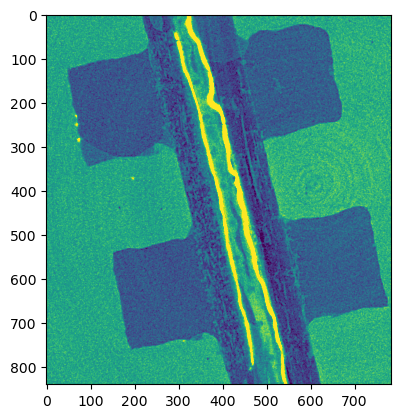

In [38]:
plt.imshow(im[:,:,500], vmin=immin, vmax=immax)

In [26]:
test = im[:,:,500].copy()

In [91]:
rotangle = -13
# testrot = sp.ndimage.rotate(test, rotangle)

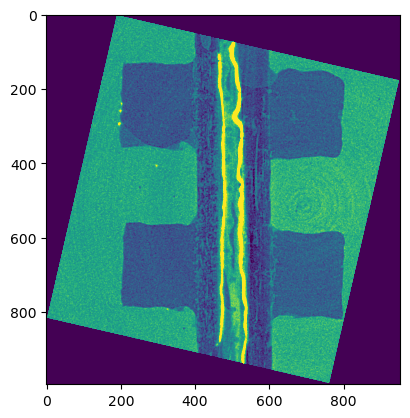

In [49]:
plt.imshow(testrot, vmin=immin, vmax=immax)

### new cropping for rotated image

In [88]:
a = 50
b = testrot.shape[0]-50
c = 50
d = testrot.shape[1]-50
e = 0
f = im.shape[2]

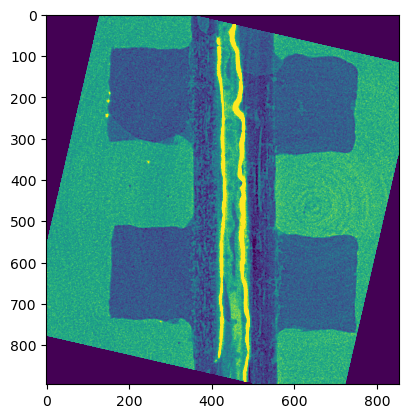

In [89]:
plt.imshow(testrot[a:b,c:d], vmin=immin, vmax=immax)

In [92]:
#save parameters
rotdict = {'sample': sample, 'angle': rotangle, 'crop_after_rot': [a,b,c,d,e,f]}
rot_info_path = os.path.join(processing_path, ''.join(['rot_params_',sample,'.json']))
with open(rot_info_path, "w") as outfile:
    json.dump(rotdict, outfile,indent = 4)

## Apply to full data set (or collect parameters and script it for ra)

In [64]:
imrot = sp.ndimage.rotate(im, -13)

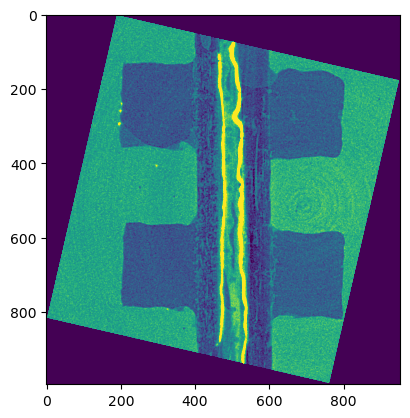

In [52]:
plt.imshow(imrot[:,:,500], vmin=immin, vmax=immax)